Progetto Data Mining - Bank Marketing Dataset.

**Studente:** Lepera Antonio
**Matricola:** 251898
**Corso:** Ingegneria Informatica - III Anno

**Obiettivo del progetto:**
Predire la variabile target "y" (se un cliente sottoscriverà un deposito bancario a termine) in funzione degli altri attributi, utilizzando algoritmi di classificazione.

**Dataset:** Bank Marketing Dataset - UCI
**Link:** https://archive.ics.uci.edu/dataset/222/bank+marketing

In [ ]:
import numpy as np
import pandas as pd


# Per la riproducibilità dei risultati
np.random.seed(42)

# Visualizzazione
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick',labelsize=12)



Fase 1: Lettura dei dati di input

In [ ]:
# Si carica il dataset dal file CSV.
# Il parametro sep=';' indica che i valori sono separati da punto e virgola
df = pd.read_csv('bank-full.csv', sep=';')

# Si stampano le dimensioni del dataset: (righe, colonne)
print(f'Righe: {df.shape[0]}')
print(f'Colonne: {df.shape[1]}')

Righe: 45211
Colonne: 17


In [ ]:
# Si vsiualizzano le prime 5 righe del dataset
# per capire com'è strutturato
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
# info() mostra per ogni colonna:
# - il nome
# - quanti valori non nulli contiene
# - il tipo di dato (int64, object, ecc.)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
# describe() calcola automaticamente le statistiche principali
# per ogni colonna numerica: media, deviazione standard,
# valore minimo, massimo e i quartili (25%, 50%, 75%).
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Grazie alla funzione describe() possiamo vedere che:
-  **balance** ha minimo -8019 quindi alcuni clienti hanno saldo negativo (e quindi debiti);
- **pdays** ha minimo -1 quindi il cliente non è mai stato contattato prima;
- **duration** ha minimo 0 quindi alcune chiamate sono durate 0 secondi;
- **campaign** ha massimo 63 quindi un cliente è stato contattato 63 volte

## 2. Data Exploration
### 2.1 Analisi della variabile target y

In [ ]:
# Si contano quanti clienti hanno risposto 'yes' e quanti 'no'
target_counts = df['y'].value_counts()
print('Distribuzione della variabile target y:')
print(target_counts)
print(f'\nPercentuale yes: {target_counts["yes"] / len(df) * 100:.2f}%')
print(f'Percentuale no:  {target_counts["no"]  / len(df) * 100:.2f}%')

Distribuzione della variabile target y:
y
no     39922
yes     5289
Name: count, dtype: int64

Percentuale yes: 11.70%
Percentuale no:  88.30%


#### Grafico della distribuzione di y

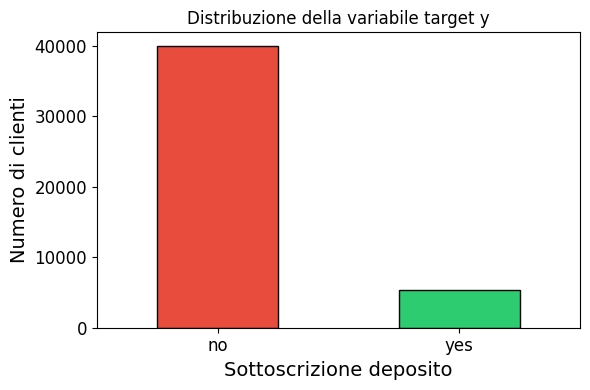

In [ ]:
# Si crea un grafico a barre per visualizzare
# lo sbilanciamento tra le due classi
plt.figure(figsize=(6, 4))
target_counts.plot(kind='bar',
                   color=['#e74c3c', '#2ecc71'],
                   edgecolor='black')

plt.title('Distribuzione della variabile target y')
plt.xlabel('Sottoscrizione deposito')
plt.ylabel('Numero di clienti')

# Si ruotano le etichette sull'asse X per renderle leggibili
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

È evidente il forte squilibrio tra le classi: la classe **no** rappresenta l'88,30% dei campioni, mentre la classe **yes** solo l'11,70% ed è il fenomeno noto come **class imbalance**. Quindi l'accuracy da sola non è sufficiente per valutare i modelli e, di conseguenza, verranno utilizzati anche Precision, Recall e F1-Score.

### 2.2 Analisi delle variabili numeriche

In [ ]:
# Si selezionano solo le colonne numeriche per analizzarle separatamente da quelle categoriche
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print('Variabili numeriche:', num_cols)
print(f'Totale: {len(num_cols)} colonne')

Variabili numeriche: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Totale: 7 colonne


#### Istogrammi delle variabili numeriche

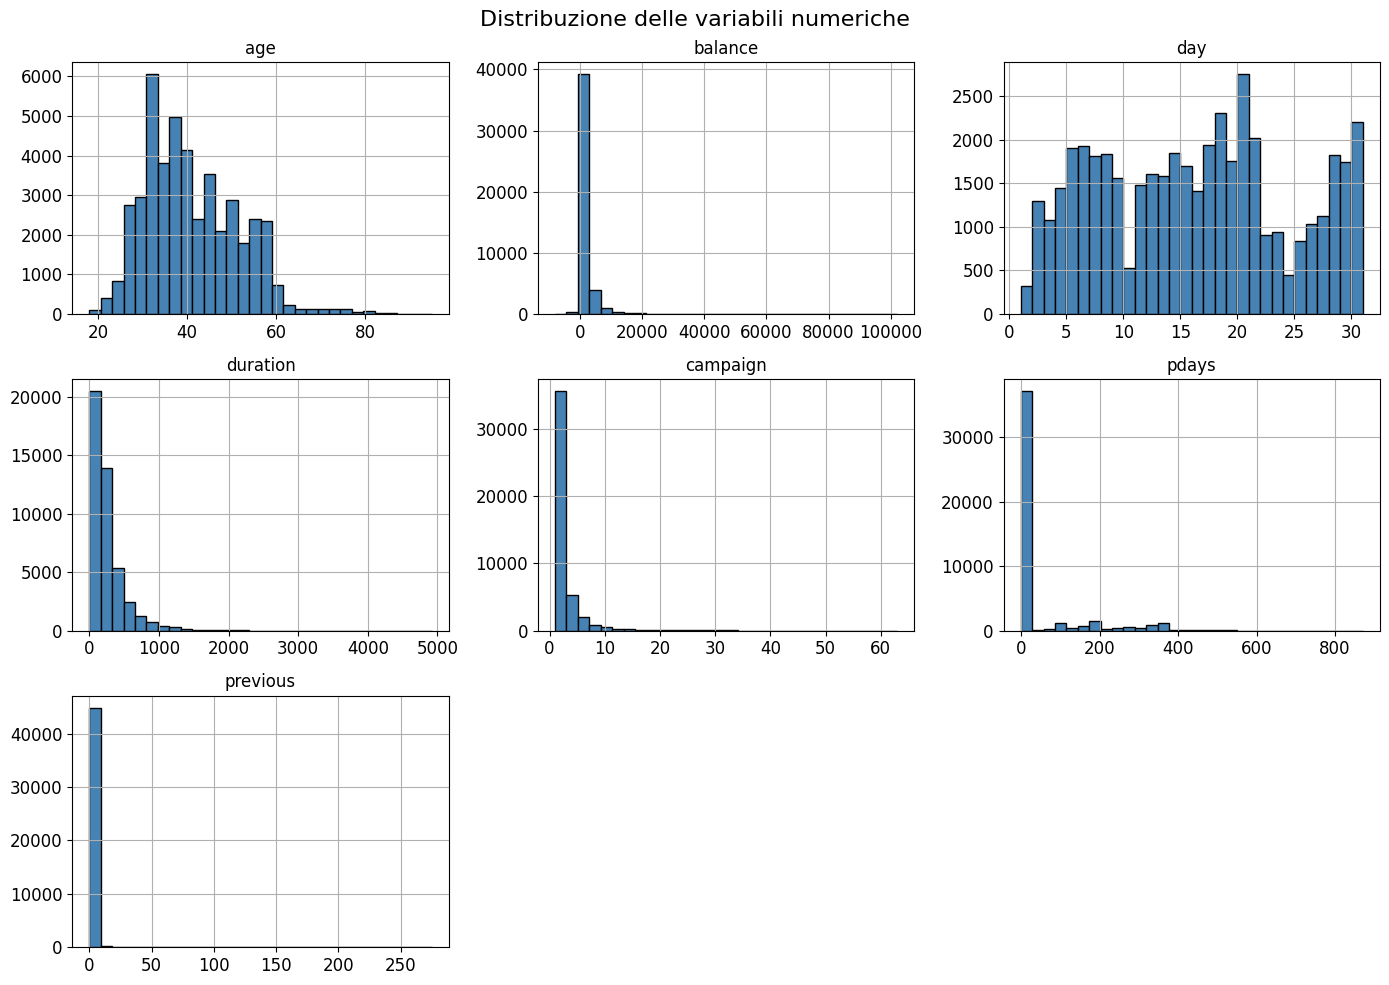

In [ ]:
# Si crea un istogramma per ogni variabile numerica.
# Un istogramma mostra come sono distribuiti i valori
# di una variabile: sull'asse X i valori, sull'asse Y
# quante volte compaiono nel dataset.
df[num_cols].hist(figsize=(14, 10),
                  bins=30,
                  edgecolor='black',
                  color='steelblue')

plt.suptitle('Distribuzione delle variabili numeriche', fontsize=16)
plt.tight_layout()
plt.show()

Dall'analisi degli istogrammi emerge che:
- **age**: La distribuzione è quasi simmetrica, clienti prevalentemente tra 25 e 60 anni;
- **balance**: è fortemente sbilanciata a destra (quasi tutti i clienti hanno saldo vicino allo zero);
- **duration**: la maggior parte delle chiamate è breve, con pochi casi di chiamate molto lunghe;
- **campaign**: quasi tutti i clienti sono stati contattati poche volte; il massimo di 63 è un outlier;
- **pdays**: la barra dominante a sinistra include i valori -1 (clienti mai contattati in precedenza);
- **previous**: la grande maggioranza dei clienti non aveva contatti precedenti

#### Boxplot delle variabili numeriche

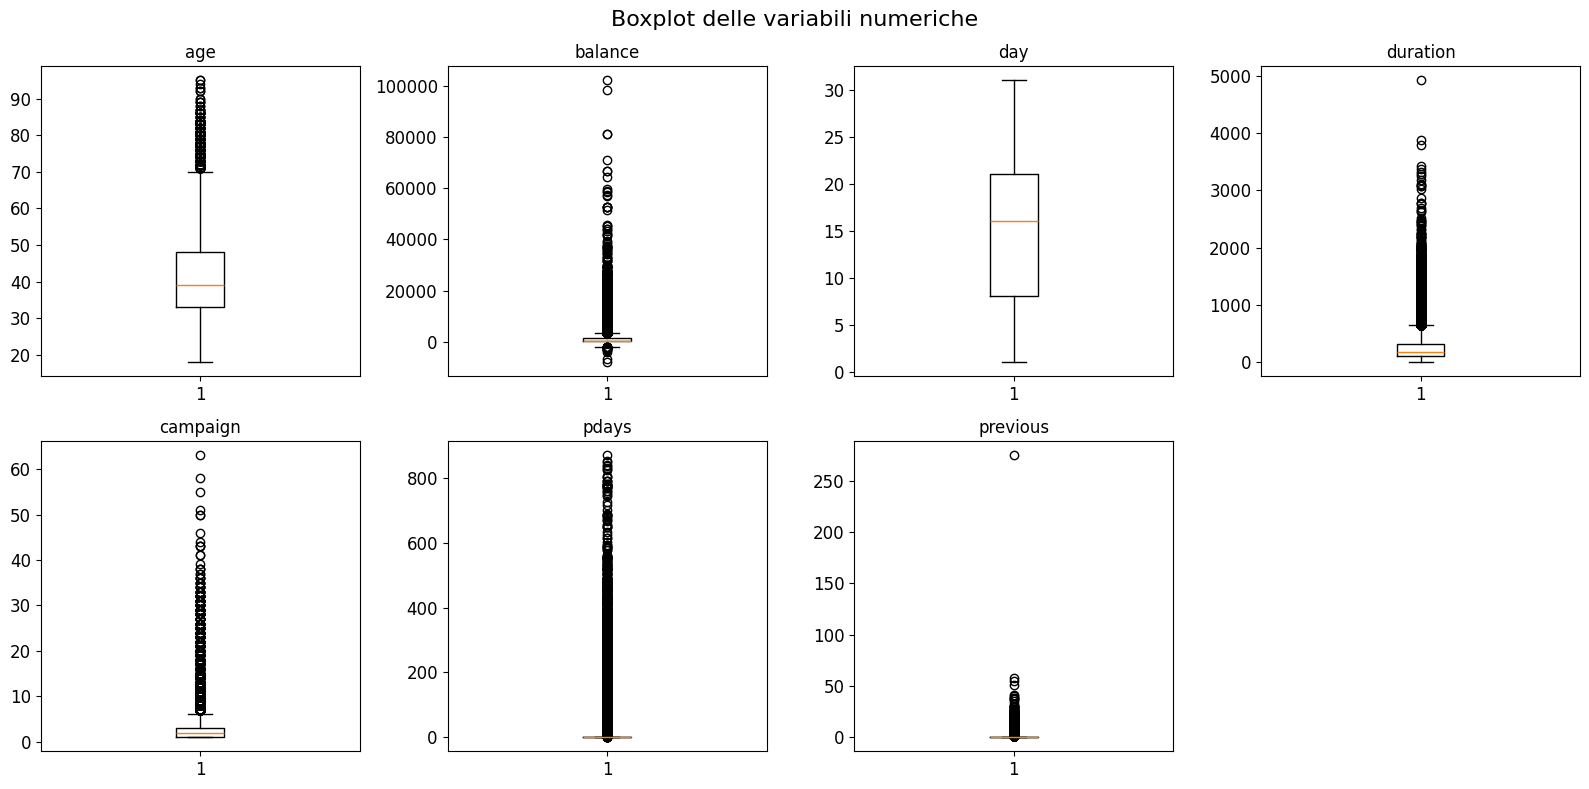

In [ ]:
# I boxplot mostrano la distribuzione di una variabile evidenziando:
# - La mediana (linea centrale)
# - Il 25° e 75° percentile (bordi del rettangolo)
# - I valori anomali/outlier (puntini oltre)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].boxplot(df[col].dropna())
    axes[i].set_title(col)

axes[7].set_visible(False)

plt.suptitle('Boxplot delle variabili numeriche', fontsize=16)
plt.tight_layout()
plt.show()

I boxplot confermano la presenza di outlier in diverse variabili:
- **balance**: alcuni clienti hanno saldi molto elevati rispetto alla mediana;
- **duration**: alcune chiamate durano migliaia di secondi;
- **campaign**: un cliente è stato contattato fino a 63 volte;
- **previous**: un cliente aveva fino a 275 contatti precedenti;

#### Matrice di correlazione

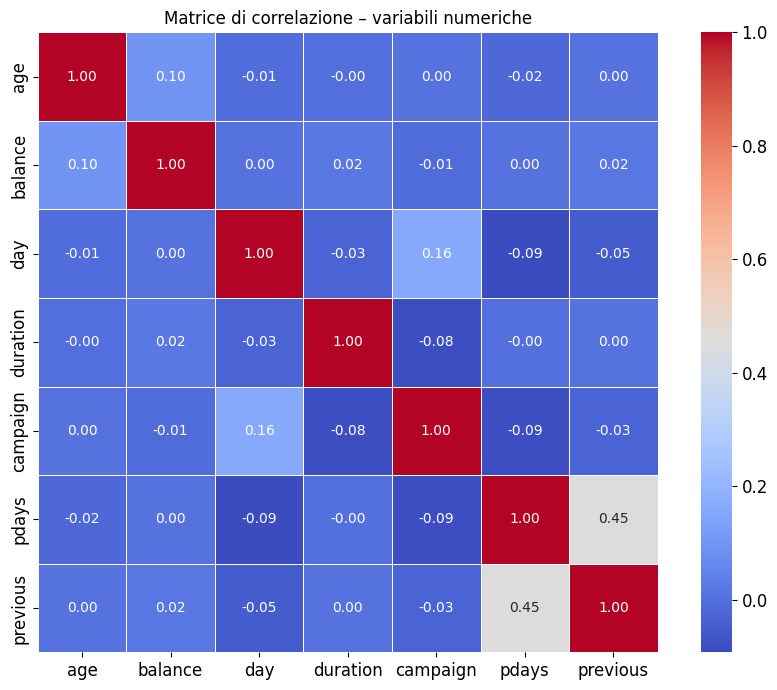

In [ ]:
# La matrice di correlazione misura quanto due variabili numeriche
# sono "legate" tra loro. Il valore va da -1 a +1:
# - vicino a +1: quando una cresce, l'altra cresce
# - vicino a -1: quando una cresce, l'altra decresce
# - vicino a  0: le due variabili non sono correlate
plt.figure(figsize=(9, 7))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix,
            annot=True,      # mostra i valori numerici nelle celle
            fmt='.2f',       # arrotonda a 2 decimali
            cmap='coolwarm', # rosso = correlazione positiva, blu = negativa
            square=True,
            linewidths=0.5)

plt.title('Matrice di correlazione – variabili numeriche')
plt.tight_layout()
plt.show()

### 2.3 Matrice di correlazione

La matrice di correlazione mostra il grado di relazione lineare tra le variabili numeriche.
L'unica correlazione è tra **pdays** e **previous** (0.45):
chi è stato contattato in passato tende ad avere più contatti precedenti registrati.
Tutte le altre coppie di variabili mostrano correlazioni molto basse (vicine a 0),
il che indica che le feature numeriche sono sostanzialmente indipendenti tra loro.

### 2.4 Analisi delle variabili categoriche

In [ ]:
# Si selezionano le colonne di tipo 'object' (testo/categoriche)
# e si esclude la variabile target 'y' che verrà analizzata successivamente
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
cat_cols.remove('y')
print('Variabili categoriche:', cat_cols)
print(f'Totale: {len(cat_cols)} colonne')

Variabili categoriche: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Totale: 9 colonne


#### Distribuzione delle variabili categoriche rispetto a y

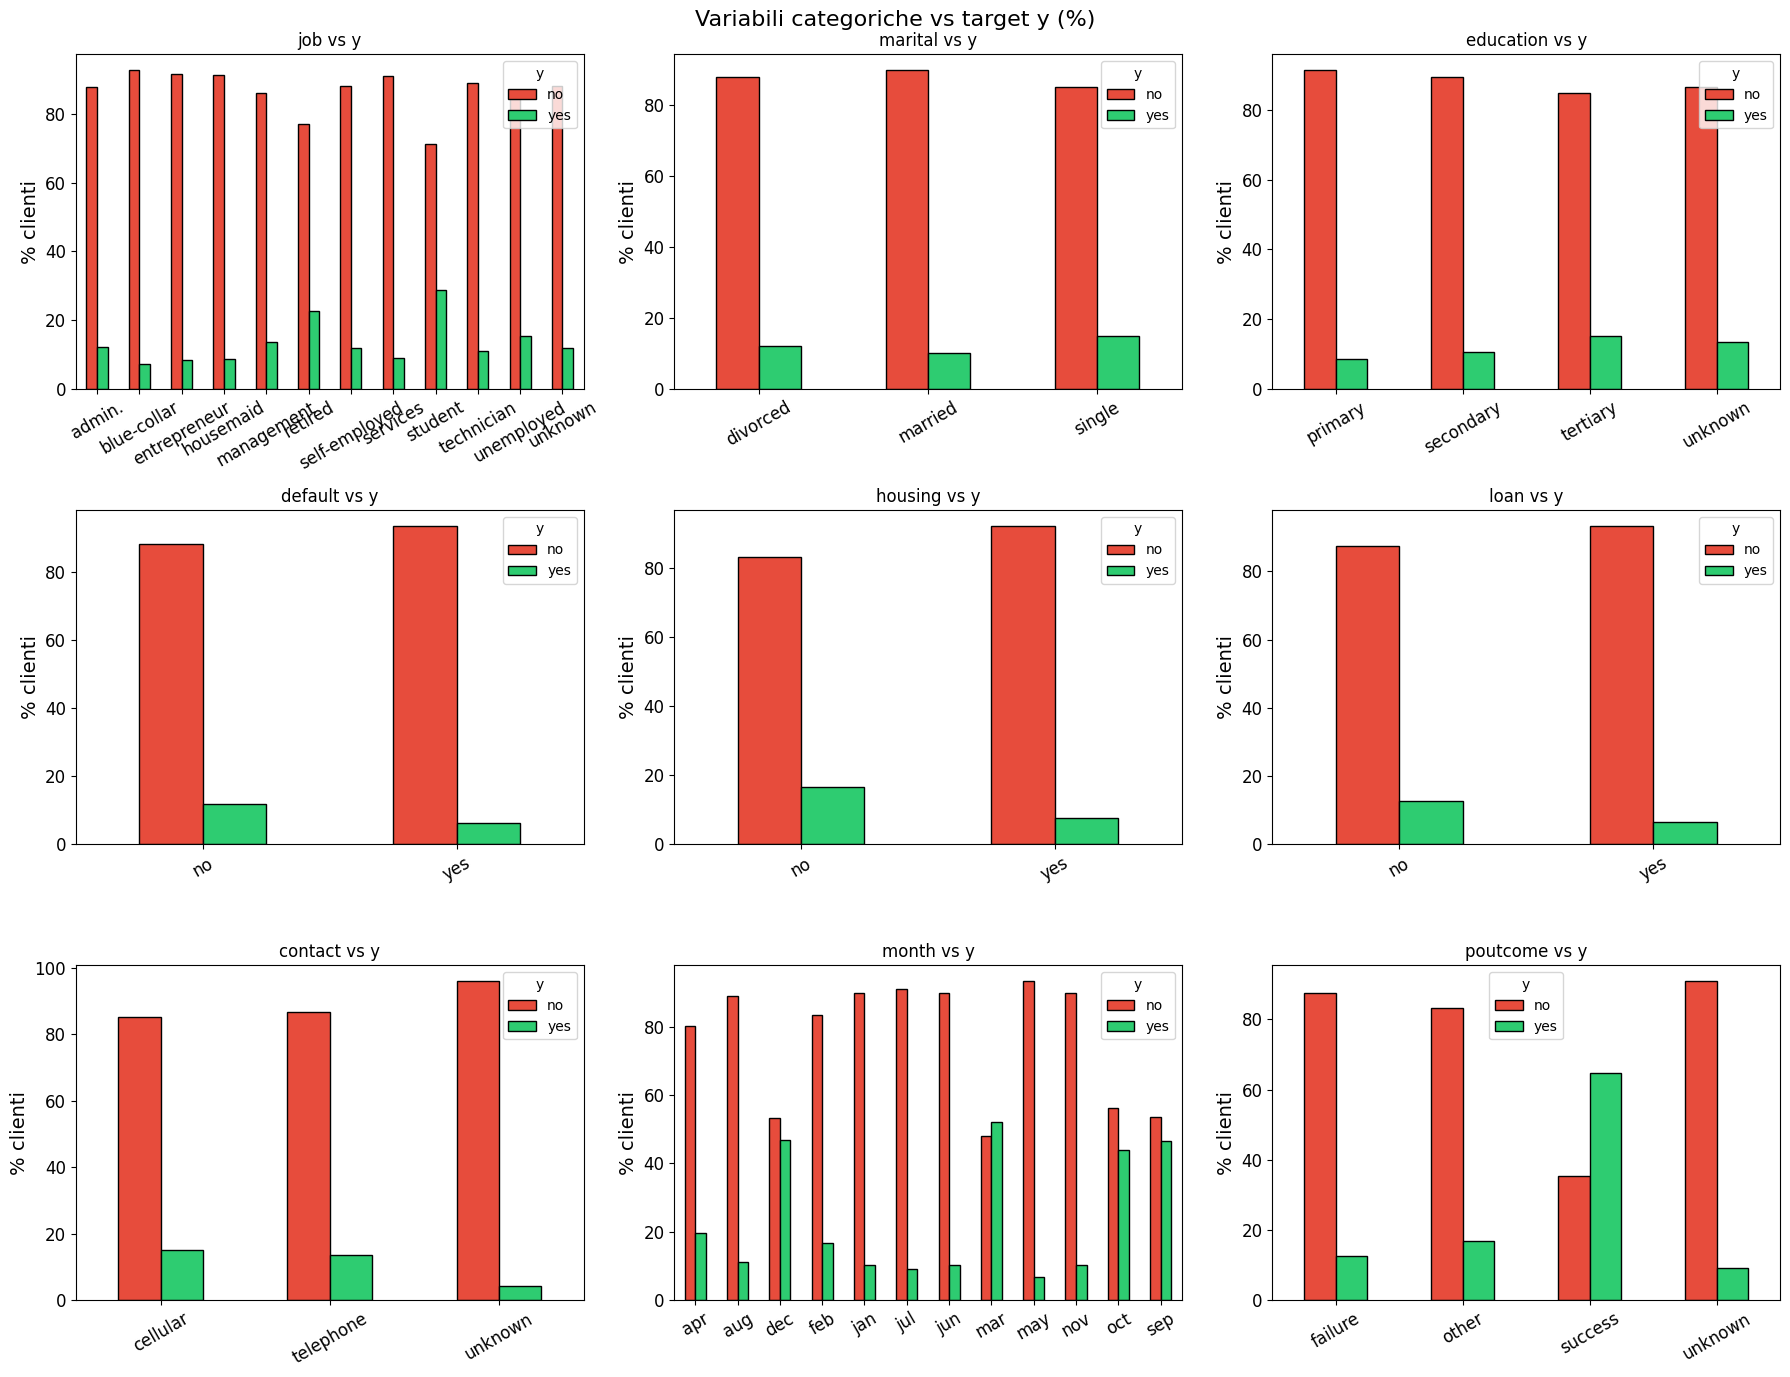

In [ ]:
# Per ogni variabile categorica si crea un grafico a barre
# che mostra la percentuale di 'yes' e 'no' per ogni categoria.
# Permette di capire quali categorie sono più associate
# alla sottoscrizione del deposito.
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    # crosstab calcola la tabella di contingenza tra due variabili
    # normalize='index' converte i conteggi in percentuali per riga
    ct = pd.crosstab(df[col], df['y'], normalize='index') * 100
    ct.plot(kind='bar',
            ax=axes[i],
            color=['#e74c3c', '#2ecc71'],
            edgecolor='black')
    axes[i].set_title(f'{col} vs y')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('% clienti')
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend(title='y', labels=['no', 'yes'])

plt.suptitle('Variabili categoriche vs target y (%)', fontsize=16)
plt.tight_layout()
plt.show()

Dall'analisi delle variabili categoriche emergono osservazioni importanti:
- **job**: studenti e pensionati mostrano i tassi di yes più elevati
- **housing** e **loan**: i clienti senza mutuo o prestiti personali sono più propensi ad accettare
- **contact**: i contatti via cellulare sono più efficaci rispetto al telefono fisso
- **month**: marzo, settembre, ottobre e dicembre mostrano tassi di yes significativamente più alti
- **poutcome**: chi aveva già risposto positivamente a una campagna precedente (success)
  ha una probabilità di yes di circa il 65% — è la variabile categorica più predittiva

### 2.5 Analisi dei valori mancanti

In [ ]:
# Nel dataset Bank Marketing i valori mancanti non sono NaN
# ma sono codificati con la stringa 'unknown' nelle variabili categoriche.
# Si contano quanti 'unknown' ci sono per ogni colonna.
print('Valori NaN nel dataset:')
print(df.isnull().sum().sum(), '→ nessun valore NaN')

print('Occorrenze di "unknown" nelle variabili categoriche:')
for col in cat_cols:
    n = (df[col] == 'unknown').sum()
    perc = n / len(df) * 100
    if n > 0:
        print(f'  {col:12s}: {n:5d} righe ({perc:.1f}%)')

Valori NaN nel dataset:
0 → nessun valore NaN
Occorrenze di "unknown" nelle variabili categoriche:
  job         :   288 righe (0.6%)
  education   :  1857 righe (4.1%)
  contact     : 13020 righe (28.8%)
  poutcome    : 36959 righe (81.7%)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 2.5 Analisi dei valori mancanti

Il dataset non contiene valori NaN classici. I valori mancanti sono
codificati con la stringa 'unknown' nelle variabili categoriche:
- **job** (0.6%) e **education** (4.1%): percentuali trascurabili
- **contact** (28.8%): tipo di contatto non sempre registrato
- **poutcome** (81.7%): la maggior parte dei clienti non aveva
  campagne precedenti, quindi l'esito è naturalmente sconosciuto

Gli 'unknown' non verranno rimossi né sostituiti: durante il preprocessing,
il One-Hot Encoding li tratterà come una categoria aggiuntiva,
preservando così l'informazione e tutte le righe del dataset.

## 3. Data Preprocessing
### 3.1 Codifica della variabile target

In [ ]:
# La variabile target y contiene valori testuali 'yes' e 'no'.
# Si convertono yes -> 1, no -> 0
df['y'] = df['y'].map({'yes': 1, 'no': 0})

print(df['y'].value_counts())

y
0    39922
1     5289
Name: count, dtype: int64


### 3.2 Gestione del valore speciale pdays

In [ ]:
# pdays = -1 significa che il cliente non era mai stato contattato
# in una campagna precedente. Questo valore speciale può confondere
# i modelli perché -1 non ha un significato numerico reale.
# Si crea una nuova colonna binaria 'contacted_before'
# che vale 1 se il cliente era già stato contattato, 0 altrimenti.
# Poi sostituiamo -1 con 0 in pdays.

df['contacted_before'] = (df['pdays'] != -1).astype(int)
df['pdays'] = df['pdays'].replace(-1, 0)

print(f'\nClienti mai contattati prima: {(df["contacted_before"] == 0).sum()}')
print(f'Clienti già contattati prima: {(df["contacted_before"] == 1).sum()}')



Clienti mai contattati prima: 36954
Clienti già contattati prima: 8257


### 3.3 One-Hot Encoding delle variabili categoriche

In [ ]:
# Il One-Hot Encoding crea una colonna binaria (0/1) per ogni
# categoria.
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

print(f'Colonne prima dell encoding: {df.shape[1]}')
print(f'Colonne dopo  l encoding:    {df_encoded.shape[1]}')
print(f'\nPrime 20 colonne del dataset codificato:')
print(df_encoded.columns.tolist()[:44])

Colonne prima dell encoding: 18
Colonne dopo  l encoding:    44

Prime 20 colonne del dataset codificato:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'y', 'contacted_before', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'job_unknown', 'marital_married', 'marital_single', 'education_secondary', 'education_tertiary', 'education_unknown', 'default_yes', 'housing_yes', 'loan_yes', 'contact_telephone', 'contact_unknown', 'month_aug', 'month_dec', 'month_feb', 'month_jan', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep', 'poutcome_other', 'poutcome_success', 'poutcome_unknown']


### 3.4 Separazione features e target

In [ ]:
# Si separano le feature (X) dalla variabile target (y).
# X contiene tutte le colonne tranne 'y'
# y contiene solo la colonna target da predire
X = df_encoded.drop('y', axis=1)
y = df_encoded['y']

print(f'Feature (X): {X.shape[1]} colonne, {X.shape[0]} righe')
print(f'Target  (y): {y.shape[0]} valori')

Feature (X): 43 colonne, 45211 righe
Target  (y): 45211 valori


### 3.5 Train/Test Split

In [ ]:
from sklearn.model_selection import train_test_split

# Si divide il dataset in due parti:
# - Training set (80%): usato per addestrare i modelli
# - Test set (20%): usato per valutare le prestazioni finali
#
# stratify=y è fondamentale con dataset sbilanciati:
# garantisce che la proporzione 88%/12% tra no e yes
# sia mantenuta sia nel training che nel test set.
# Senza stratify, potremmo ritrovarci con un test set
# con pochissimi 'yes' e risultati falsati.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Training set: {X_train.shape[0]} campioni ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Test set:     {X_test.shape[0]} campioni ({X_test.shape[0]/len(X)*100:.0f}%)')
print(f'\nDistribuzione classi nel training set:')
print((y_train.value_counts(normalize=True) * 100).round(2))
print(f'\nDistribuzione classi nel test set:')
print((y_test.value_counts(normalize=True) * 100).round(2))

Training set: 36168 campioni (80%)
Test set:     9043 campioni (20%)

Distribuzione classi nel training set:
y
0    88.3
1    11.7
Name: proportion, dtype: float64

Distribuzione classi nel test set:
y
0    88.3
1    11.7
Name: proportion, dtype: float64


### 3.6 Normalizzazione delle feature

In [ ]:
from sklearn.preprocessing import StandardScaler

# Le feature numeriche hanno scale molto diverse tra loro:
# - age va da 18 a 95
# - balance va da -8019 a 102127
# - duration va da 0 a 4918
# Alcuni algoritmi (KNN, SVM, Logistic Regression) sono sensibili
# alla scala delle feature: una variabile con valori grandi
# dominerebbe sulle altre.
# StandardScaler riporta ogni feature a media=0 e std=1,
# mettendole tutte sulla stessa scala.
# Si addestra lo scaler SOLO sul training set
# e lo applichiamo poi anche al test set.
# Se lo addestrassimo su tutto il dataset, il modello
# "vedrebbe" informazioni del test set durante il training
# (data leakage).

scaler = StandardScaler()

# fit_transform: calcola media e std sul training set e trasforma
X_train_scaled = scaler.fit_transform(X_train)

# transform: usa la media e std già calcolate sul training set
X_test_scaled = scaler.transform(X_test)

## 4. Applicazione degli algoritmi di classificazione

In questa fase applichiamo i principali algoritmi di classificazione:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. K-Nearest Neighbors (KNN)
5. Support Vector Machine (SVM)
6. Naive Bayes

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import cross_val_score

# Si crea un dizionario con tutti i classificatori
# in modo da iterare su di essi con un ciclo
classifiers = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree'       : DecisionTreeClassifier(random_state=42),
    'Random Forest'       : RandomForestClassifier(n_estimators=100, random_state=42),
    'KNN'                 : KNeighborsClassifier(n_neighbors=5),
    'SVM'                 : SVC(kernel='rbf', random_state=42),
    'Naive Bayes'         : GaussianNB()
}

### 4.1 Addestramento e valutazione dei modelli

In [ ]:
# Per ogni classificatore:
# 1. Viene addestrato sul training set
# 2. Si fanno le predizioni sul test set
# 3. Si calcolano le metriche di valutazione
# 4. Si esegue la cross-validation sul training set

results = []

for name, clf in classifiers.items():

    # Addestramento sul training set
    clf.fit(X_train_scaled, y_train)

    # Predizione sul test set
    y_pred = clf.predict(X_test_scaled)

    # Calcolo delle metriche
    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec  = recall_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred)

    # Cross-validation a 3 fold sul training set
    # Serve a verificare che il modello non sia in overfitting
    cv = cross_val_score(clf, X_train_scaled, y_train,
                         cv=3, scoring='accuracy')
    cv_mean = cv.mean()

    results.append({
        'Modello'    : name,
        'Accuracy'   : round(acc,  4),
        'Precision'  : round(prec, 4),
        'Recall'     : round(rec,  4),
        'F1-Score'   : round(f1,   4),
        'CV Accuracy': round(cv_mean, 4)
    })

    print(f'{name:22s} | Acc: {acc:.3f} | Prec: {prec:.3f} | Rec: {rec:.3f} | F1: {f1:.3f} | CV: {cv_mean:.3f}')

# Si salvano i risultati in un DataFrame per analizzarli meglio
results_df = pd.DataFrame(results).set_index('Modello')

Logistic Regression    | Acc: 0.901 | Prec: 0.646 | Rec: 0.349 | F1: 0.453 | CV: 0.902
Decision Tree          | Acc: 0.874 | Prec: 0.462 | Rec: 0.480 | F1: 0.471 | CV: 0.873
Random Forest          | Acc: 0.906 | Prec: 0.671 | Rec: 0.391 | F1: 0.494 | CV: 0.906
KNN                    | Acc: 0.894 | Prec: 0.587 | Rec: 0.308 | F1: 0.404 | CV: 0.894
SVM                    | Acc: 0.902 | Prec: 0.672 | Rec: 0.323 | F1: 0.437 | CV: 0.901
Naive Bayes            | Acc: 0.855 | Prec: 0.404 | Rec: 0.492 | F1: 0.444 | CV: 0.852


I risultati mostrano accuracy elevata per tutti i modelli, ma questo è
parzialmente dovuto allo sbilanciamento delle classi. Il F1-Score è
la metrica più significativa: il Random Forest ottiene il valore più
alto (0.494), seguito dal Decision Tree (0.471).
La CV Accuracy è allineata con la Test Accuracy per tutti i modelli,
il che indica assenza di overfitting.

### 4.2 Confusion Matrix

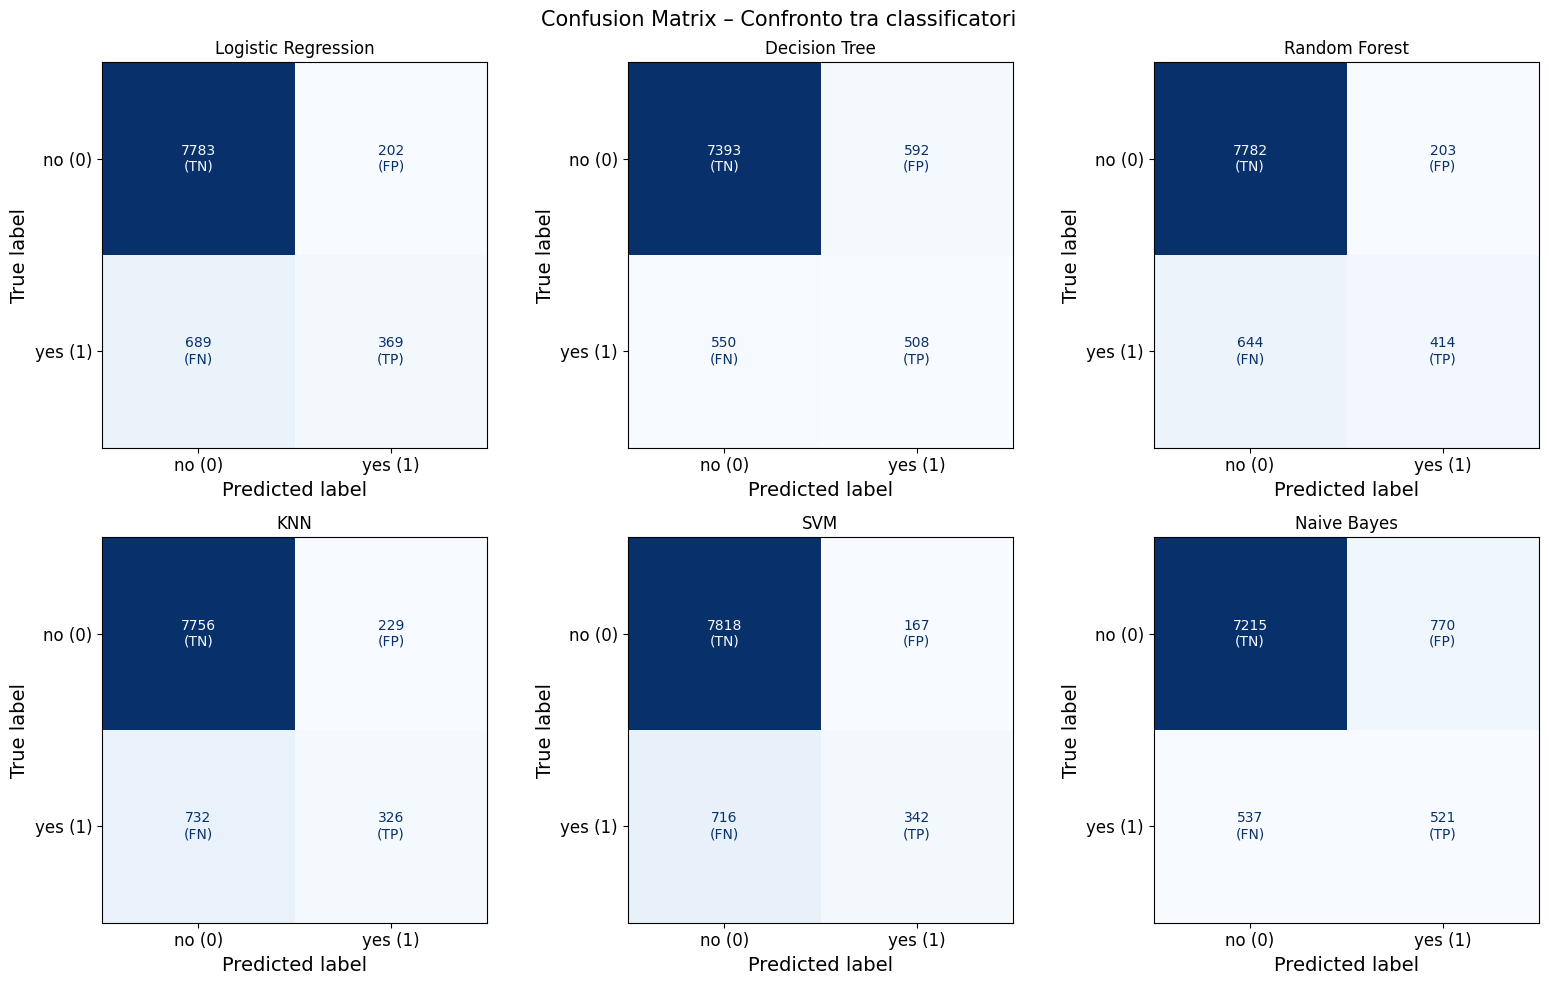

In [ ]:
# La Confusion Matrix mostra nel dettaglio gli errori di ogni modello:
# - Vero Positivo (TP): predetto yes, era yes
# - Vero Negativo (TN): predetto no,  era no
# - Falso Positivo (FP): predetto yes, era no
# - Falso Negativo (FN): predetto no,  era yes

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (name, clf) in enumerate(classifiers.items()):
    y_pred = clf.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)

    # Estraiamo i 4 valori della matrice
    tn, fp, fn, tp = cm.ravel()

    # Creiamo il display della matrice
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['no (0)', 'yes (1)']
    )
    disp.plot(ax=axes[i], colorbar=False, cmap='Blues')

    # Si personalizza il testo all'interno delle 4 celle
    # e si usa \n per andare a capo ed evitare che il testo esca dai margini
    disp.text_[0, 0].set_text(f"{tn}\n(TN)")
    disp.text_[0, 1].set_text(f"{fp}\n(FP)")
    disp.text_[1, 0].set_text(f"{fn}\n(FN)")
    disp.text_[1, 1].set_text(f"{tp}\n(TP)")

    axes[i].set_title(name, fontsize=12)

plt.suptitle('Confusion Matrix – Confronto tra classificatori', fontsize=15)
plt.tight_layout()
plt.show()

Le confusion matrix mostrano che tutti i modelli faticano con la classe
minoritaria 'yes', a causa dello sbilanciamento del dataset.
Il Naive Bayes identifica il maggior numero di clienti yes (521/1058)
ma genera molti falsi allarmi (770). Il Random Forest ottiene il miglior
compromesso tra yes identificati (414) e falsi allarmi (203).

## 5. Analisi dei risultati
### 5.1 Confronto grafico delle metriche

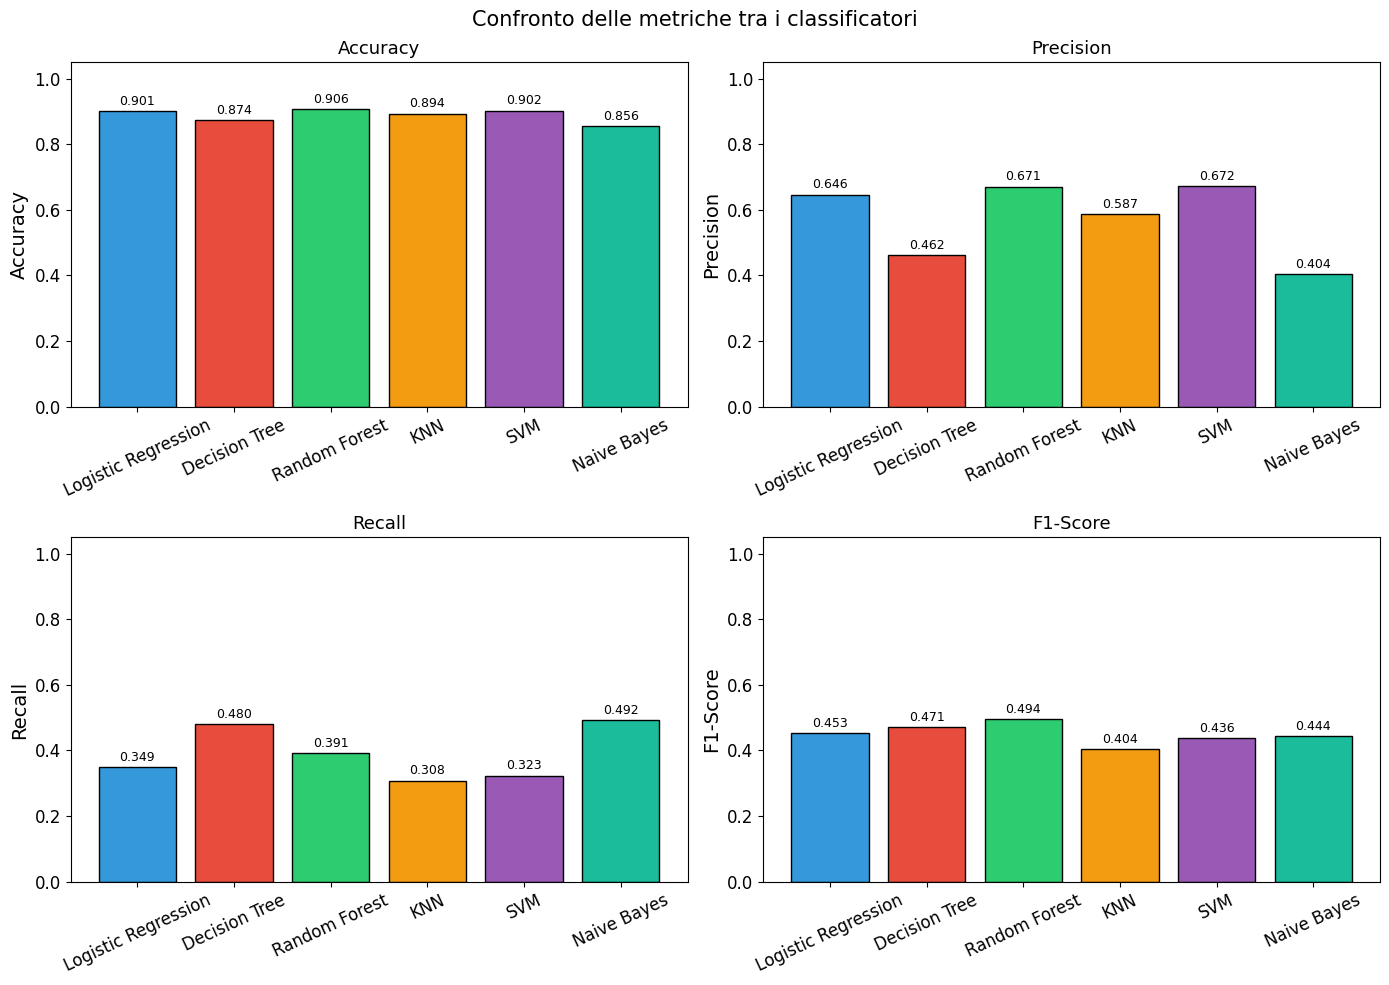

In [ ]:
# Si crea un grafico a barre per confrontare visivamente
# le 4 metriche principali tra tutti i modelli
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

# Colori diversi per ogni modello
colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c']

for i, metric in enumerate(metrics):
    vals   = results_df[metric]
    models = results_df.index
    bars   = axes[i].bar(models, vals, color=colors, edgecolor='black')
    axes[i].set_title(metric, fontsize=13)
    axes[i].set_ylim(0, 1.05)
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=25)

    # Si aggiunge il valore numerico sopra ogni barra
    for bar, val in zip(bars, vals):
        axes[i].text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.01,
            f'{val:.3f}',
            ha='center', va='bottom', fontsize=9
        )

plt.suptitle('Confronto delle metriche tra i classificatori', fontsize=15)
plt.tight_layout()
plt.show()

Il confronto grafico conferma che:
- L'**accuracy** è simile per tutti i modelli e non è discriminante
- In **precision** emergono Random Forest e SVM: quando predicono yes,
  raramente sbagliano
- In **recall** Naive Bayes e Decision Tree identificano più clienti yes
- Il **F1-Score** premia il Random Forest come modello più equilibrato

### 5.2 Feature Importance – Random Forest

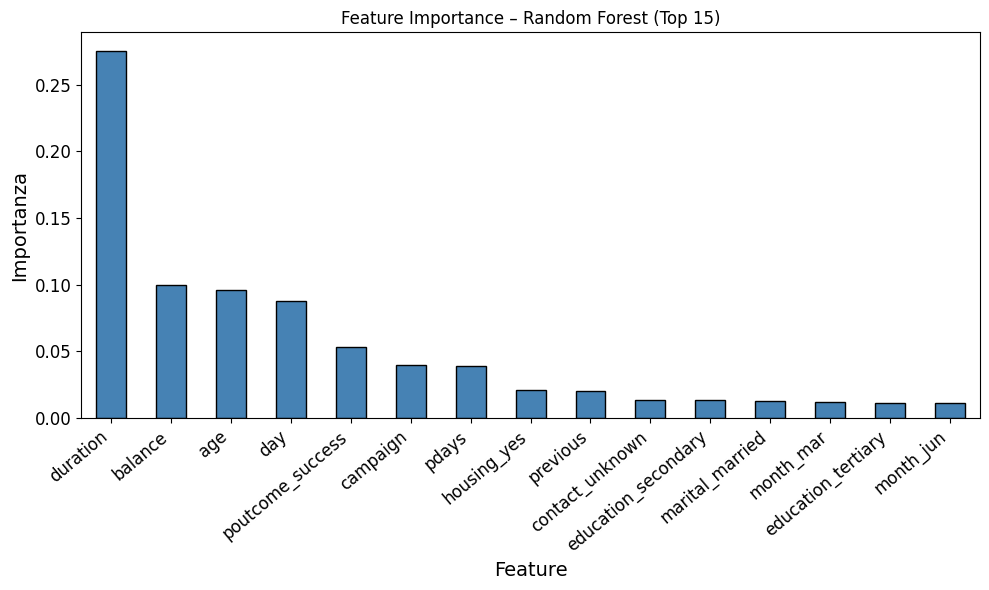

In [ ]:
# Il Random Forest permette di calcolare l'importanza di ogni feature,
# cioè quanto ciascuna variabile ha contribuito alle decisioni del modello.
# Valori più alti = feature più utile per la classificazione.
rf_clf = classifiers['Random Forest']
importances = pd.Series(rf_clf.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
top_features.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Feature Importance – Random Forest (Top 15)')
plt.ylabel('Importanza')
plt.xlabel('Feature')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

La feature più importante risulta **duration** (0.275), ovvero la durata
dell'ultima chiamata. Tuttavia questa variabile è nota solo a posteriori
(dopo aver effettuato la chiamata), quindi in un contesto applicativo reale
andrebbe esclusa per evitare data leakage.
Seguono **balance**, **age** e **day** come variabili numeriche più rilevanti.
**poutcome_success** (0.053) conferma quanto osservato nell'esplorazione:
i clienti che avevano già risposto positivamente in passato sono i più
propensi a sottoscrivere il deposito.

### 5.3 Conclusioni finali

In [ ]:
# Tabella riepilogativa finale ordinata per F1-Score
print('Risultati finali ordinati per F1-Score:')
print(results_df.sort_values('F1-Score', ascending=False).to_string())

Risultati finali ordinati per F1-Score:
                     Accuracy  Precision  Recall  F1-Score  CV Accuracy
Modello                                                                
Random Forest          0.9063     0.6710  0.3913    0.4943       0.9059
Decision Tree          0.8737     0.4618  0.4802    0.4708       0.8728
Logistic Regression    0.9015     0.6462  0.3488    0.4530       0.9020
Naive Bayes            0.8555     0.4036  0.4924    0.4436       0.8524
SVM                    0.9024     0.6719  0.3233    0.4365       0.9007
KNN                    0.8937     0.5874  0.3081    0.4042       0.8938


## Conclusioni

Il progetto ha affrontato un task di classificazione binaria per predire
se un cliente sottoscriverà un deposito bancario a termine (variabile target **y**),
utilizzando il Bank Marketing Dataset dell'UCI.

### Risultati principali

- Il **Random Forest** ha ottenuto il miglior F1-Score (0.494),
  confermandosi il modello più equilibrato tra precision e recall
- Il **Decision Tree** si è rivelato un buon compromesso (F1: 0.471),
  con il vantaggio di essere facilmente interpretabile
- Il **Naive Bayes** ha la recall più alta (0.492) ma genera
  molti falsi allarmi (precision: 0.404)
- Il **KNN** è risultato il modello meno performante (F1: 0.404)
